In [ ]:
import geopandas as gpd
import pandas as pd
import numpy as np
from shapely.geometry import Point
from pathlib import Path
import requests
import time
import matplotlib.pyplot as plt




# Region boundaries and random weather locations

In NVE Atlas, we retrieve Budområder and NVE_Region from NVE's REST services (????) and save them as shapefiles.

The assignment's precipitation regions are grouped as East (Øst) = RS + RØ, West (Vest) = RV, and North (Nord) = RM + RN. These are groups of NVE regions (!!!)

----------------------------------

## Retreive the NVE regions, then rainfall areas

Read the shapefil using geopandas and using the encoding as "utf-8" to handle Norwegian characters correctly.

In [5]:
regions = gpd.read_file("../data/shapefiles/NVE_region.shp", encoding = 'utf-8')
# . means current directory, .. means parent directory

print("Coordinate Reference System:", regions.crs)  # Coordinate Reference System
print("Column names:", regions.columns.tolist())  # List of column names

regions

Coordinate Reference System: EPSG:25833
Column names: ['OBJECTID', 'REGION', 'REGIONNAVN', 'POSTNUMMER', 'POSTSTED', 'BESØKSADR', 'ADRESSE', 'geometry']


,OBJECTID,REGION,REGIONNAVN,POSTNUMMER,POSTSTED,BESØKSADR,ADRESSE,geometry
0,1.0,RV,Region Vest,6801,Førde,Naustdalsveien 1B,Postboks 53,"POLYGON ((193105.76 6929797.839, 191705.75 692..."
1,2.0,RM,Region Midt-Norge,7030,Trondheim,"Abelsgate 9, Trondheim",Abelsgate 9,"POLYGON ((391250 7388620, 392270 7386790, 3937..."
2,3.0,RN,Region Nord,8514,Narvik,Kongensgate 52-54,Kongensgate 52-54,"POLYGON ((1109096.413 7844647.502, 1105115.343..."
3,4.0,RØ,Region Øst,2307,Hamar,Vangsvegen 73,Postboks 4223,"POLYGON ((253748.22 6678130.91, 253645.58 6678..."
4,5.0,RS,Region Sør,3103,Tønsberg,Anton Jenssens gate 7,Postboks 2124,"POLYGON ((253748.22 6678130.91, 253917.63 6677..."


There are five administrative NVE regions in total, which will be used to combined into three rainfall areas:
- East (Øst) = RS + RØ
- West (Vest) = RV
- North (Nord) = RM + RN

In [6]:
# Map NVE administrative regions to precipitation regions
region_mapping = {
    "RS": "Øst",
    "RØ": "Øst",
    "RV": "Vest",
    "RM": "Nord",
    "RN": "Nord"
}

# Assign precipitation region names
precipitation_regions = regions.copy()
precipitation_regions["region"] = precipitation_regions["REGION"].map(region_mapping)

# Merge polygons belonging to the same precipitation region
precipitation_regions = precipitation_regions.dissolve(
    by="region",
    as_index=False
)

precipitation_regions[["region"]]

,region
0,Nord
1,Vest
2,Øst


## Retrieve the power zones (strømområdene)

In [7]:
electricity_areas = gpd.read_file(
    "../data/shapefiles/Budområder.shp"
)

print("CRS:", electricity_areas.crs)
print("Columns:", electricity_areas.columns.tolist())
electricity_areas

CRS: EPSG:25833
Columns: ['objectid', 'budomr', 'globalid', 'st_area(sh', 'st_perimet', 'geometry']


,objectid,budomr,globalid,st_area(sh,st_perimet,geometry
0,1.0,NO 1,NaN,6.052902e+10,1.657761e+06,"POLYGON ((337473.63 6970542.97, 337711.9 69703..."
1,2.0,NO 2,NaN,6.875969e+10,1.256473e+06,"POLYGON ((-9833.91 6726499.86, -9836 6726404.0..."
2,3.0,NO 3,NaN,1.042199e+11,1.773323e+06,"POLYGON ((308588.7 7261519.43, 313576.63 72590..."
3,4.0,NO 4,NaN,2.032500e+11,3.385499e+06,"POLYGON ((973920.93 7962739.19, 974922.77 7962..."
4,5.0,NO 5,NaN,3.334870e+10,1.106762e+06,"POLYGON ((101466.43 6881318.54, 101525.43 6881..."


There are five regions for power zones

## Generate random points for each region 

Combine power and rainfall areas to use for weather data download

In [8]:
# Standardize electricity region names
electricity_areas["region"] = (
    electricity_areas["budomr"]
    .str.replace(" ", "", regex=False)
)

# Keep only region names and geometries
electricity = electricity_areas[["region", "geometry"]]
precipitation = precipitation_regions[["region", "geometry"]]

# Ensure both datasets use the same coordinate system
precipitation = precipitation.to_crs(electricity.crs)

# Combine all eight regions
all_regions = gpd.GeoDataFrame(
    pd.concat([electricity, precipitation], ignore_index=True),
    geometry="geometry",
    crs=electricity.crs
)

print(all_regions["region"].tolist())

['NO1', 'NO2', 'NO3', 'NO4', 'NO5', 'Nord', 'Vest', 'Øst']


In [9]:
import geopandas as gpd
import pandas as pd

def generate_weather_locations(regions, n_points=1000, seed=42):
    """
    Generate random weather locations for each geographic region.
    """

    # Use an equal-area projection for spatial sampling
    regions = regions.to_crs(epsg=3035).copy()

    # Sample random points within each region
    sampled = regions[["region", "geometry"]].copy()
    sampled["geometry"] = regions.geometry.sample_points(
        size=n_points,
        rng=seed
    )

    # Convert multipoints into individual rows
    sampled = sampled.explode(
        index_parts=False
    ).reset_index(drop=True)

    # Assign a unique point ID within each region
    sampled["point_id"] = (
        sampled.groupby("region").cumcount() + 1
    )

    # Convert coordinates to WGS84 for Open-Meteo
    sampled = sampled.to_crs(epsg=4326)

    sampled["longitude"] = sampled.geometry.x
    sampled["latitude"] = sampled.geometry.y

    return sampled


weather_locations = generate_weather_locations(
    all_regions,
    n_points=1000,
    seed=42
)

print(weather_locations.groupby("region").size())

region
NO1     1000
NO2     1000
NO3     1000
NO4     1000
NO5     1000
Nord    1000
Vest    1000
Øst     1000
dtype: int64


Save the coordinates in csv file

In [10]:

# Save geographic coordinates for future API requests
output_dir = Path("../data/geography")
output_dir.mkdir(parents=True, exist_ok=True)

weather_locations[
    ["region", "point_id", "latitude", "longitude"]
].to_csv(
    output_dir / "weather_locations.csv",
    index=False
)

print("Saved locations:", len(weather_locations))
weather_locations

Saved locations: 8000


,region,geometry,point_id,longitude,latitude
0,NO1,POINT (11.68444 59.75392),1,11.684436,59.753919
1,NO1,POINT (11.65588 61.63177),2,11.655883,61.631771
2,NO1,POINT (10.48523 62.38517),3,10.485228,62.385174
3,NO1,POINT (12.12426 60.87451),4,12.124261,60.874512
4,NO1,POINT (11.80075 62.25122),5,11.800748,62.251222
...,...,...,...,...,...
7995,Øst,POINT (6.06891 59.21159),996,6.068909,59.211589
7996,Øst,POINT (11.01143 62.42831),997,11.011430,62.428313
7997,Øst,POINT (9.83699 61.59526),998,9.836991,61.595260
7998,Øst,POINT (6.42913 58.94702),999,6.429128,58.947017


## Get historical weather data from Open-Meteo (ERA5) for NO3 in 2024.

we’ll use the coordinates we’ve generated for NO3, and retrieve temperature and precipitation data from Open-Meteo. 

In [11]:
import requests
import pandas as pd

def get_era5_weather(latitude, longitude, start_date, end_date):
    """
    Download hourly ERA5 reanalysis weather data
    for a single geographic location.
    """

    url = "https://archive-api.open-meteo.com/v1/archive"

    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": start_date,
        "end_date": end_date,
        "hourly": "temperature_2m,precipitation",
        "models": "era5",
        "timezone": "UTC"
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()

    # The response is expected to be in JSON format, and we extract the "hourly" data
    data = response.json()["hourly"]

    df = pd.DataFrame(data)
    # Convert the "time" column to datetime format with UTC timezone
    df["time"] = pd.to_datetime(df["time"], utc=True)

    return df

create a region-based function that can retrieve data for multiple locations.

In [12]:

def download_region_weather(
    region,
    start_date,
    end_date,
    locations=weather_locations,
    n_locations=1
):
    """
    Download hourly ERA5 weather data for a selected region.

    Uses previously generated geographic coordinates.
    """

    region_points = locations.loc[
        locations["region"] == region
    ].head(n_locations)

    if region_points.empty:
        raise ValueError(f"No locations found for {region}")

    results = []

    for _, point in region_points.iterrows():

        weather = get_era5_weather(
            latitude=point["latitude"],
            longitude=point["longitude"],
            start_date=start_date,
            end_date=end_date
        )

        weather["region"] = region
        weather["point_id"] = point["point_id"]

        results.append(weather)

    return pd.concat(results, ignore_index=True)


We now need to retrieve data for all 1,000 locations in order to calculate regional average temperature and precipitation.

However, 1,000 separate API calls are not very efficient. 

--> Create a function such that we can retrieve ERA5 data for all 1,000 points in NO3 without having to send 1,000 separate requests.

--> Open-Meteo supports multiple coordinates in a single request.

--> Use Open-Meteo’s support for multiple coordinates in a single request and divide the points into groups of 10.

In [13]:

def download_region_weather(
    region,
    start_date,
    end_date,
    locations=weather_locations,
    batch_size=10,
    n_locations=None,
    output_dir="../data/weather"
):
    """
    Download ERA5 weather data in batches.
    Save each completed batch and skip it on future runs.
    """

    points = locations.loc[
        locations["region"] == region
    ].copy()

    if n_locations is not None:
        points = points.head(n_locations)

    if points.empty:
        raise ValueError(f"No locations found for {region}")

    if batch_size < 1:
        raise ValueError("batch_size must be at least 1")

    output_path = Path(output_dir) / region
    output_path.mkdir(parents=True, exist_ok=True)

    url = "https://archive-api.open-meteo.com/v1/archive"

    for start in range(0, len(points), batch_size):

        batch = points.iloc[start:start + batch_size]

        # Include dates and point IDs to avoid mixing datasets
        first_id = batch["point_id"].iloc[0]
        last_id = batch["point_id"].iloc[-1]

        filename = (
            f"{region}_{start_date}_{end_date}_"
            f"{first_id}_{last_id}.parquet"
        )

        filepath = output_path / filename

        # Skip previously completed batches
        if filepath.exists():
            print(f"Already saved: {filename}")
            continue

        params = {
            "latitude": ",".join(
                batch["latitude"].astype(str)
            ),
            "longitude": ",".join(
                batch["longitude"].astype(str)
            ),
            "start_date": start_date,
            "end_date": end_date,
            "hourly": "temperature_2m,precipitation",
            "models": "era5",
            "timezone": "UTC"
        }

        try:
            response = requests.get(
                url,
                params=params,
                timeout=120
            )

            if response.status_code == 429:
                print("HTTP 429: API limit reached. Stopping.")
                return

            response.raise_for_status()
            data = response.json()

        except requests.RequestException as error:
            print(f"Download stopped: {error}")
            return

        if isinstance(data, dict):
            data = [data]

        if len(data) != len(batch):
            raise ValueError("Unexpected API response count")

        results = []

        for (_, point), location_data in zip(
            batch.iterrows(), data
        ):
            df = pd.DataFrame(location_data["hourly"])

            df["time"] = pd.to_datetime(
                df["time"], utc=True
            )
            df["region"] = region
            df["point_id"] = point["point_id"]

            results.append(df)

        batch_df = pd.concat(results, ignore_index=True)

        # Save completed batch
        batch_df.to_parquet(filepath, index=False)

        print(
            f"Saved {min(start + batch_size, len(points))}"
            f"/{len(points)} locations"
        )

        time.sleep(1)

    print("Download run finished.")




In [23]:
download_region_weather(
    region="NO3",
    start_date="2024-01-01",
    end_date="2024-12-31",
    batch_size=10,
    n_locations=None # Download all available locations
)

Already saved: NO3_2024-01-01_2024-12-31_1_10.parquet
Already saved: NO3_2024-01-01_2024-12-31_11_20.parquet
Already saved: NO3_2024-01-01_2024-12-31_21_30.parquet
Already saved: NO3_2024-01-01_2024-12-31_31_40.parquet
Already saved: NO3_2024-01-01_2024-12-31_41_50.parquet
Already saved: NO3_2024-01-01_2024-12-31_51_60.parquet
Already saved: NO3_2024-01-01_2024-12-31_61_70.parquet
Already saved: NO3_2024-01-01_2024-12-31_71_80.parquet
Already saved: NO3_2024-01-01_2024-12-31_81_90.parquet
Already saved: NO3_2024-01-01_2024-12-31_91_100.parquet
Already saved: NO3_2024-01-01_2024-12-31_101_110.parquet
Already saved: NO3_2024-01-01_2024-12-31_111_120.parquet
Already saved: NO3_2024-01-01_2024-12-31_121_130.parquet
Already saved: NO3_2024-01-01_2024-12-31_131_140.parquet
Already saved: NO3_2024-01-01_2024-12-31_141_150.parquet
Already saved: NO3_2024-01-01_2024-12-31_151_160.parquet
Already saved: NO3_2024-01-01_2024-12-31_161_170.parquet
Already saved: NO3_2024-01-01_2024-12-31_171_180.pa

On the first run, I have downloaded weather data for 130 of 1,000 points in NO3 before it shows "HTTP 429: API limit reached. Stopping. Once the API allows new requests, I continued from point 131. I kept doing this until I got all ERA5-data for 1000 locations in NO3 throughout the whole 2024

Control that all data was downloaded correctly:

In [26]:
# Find all saved Parquet files for NO3
folder = Path("../data/weather/NO3")


files = sorted(folder.glob("NO3_2024-01-01_2024-12-31_*.parquet"))

print("Number of files:", len(files))

# Load and combine all batches
weather_no3 = pd.concat(
    [pd.read_parquet(file) for file in files],
    ignore_index=True
)

# Check downloaded data
print("Total rows:", len(weather_no3))
print("Unique locations:", weather_no3["point_id"].nunique())
print("Unique timestamps:", weather_no3["time"].nunique())

weather_no3

Number of files: 100
Total rows: 8784000
Unique locations: 1000
Unique timestamps: 8784


,time,temperature_2m,precipitation,region,point_id
0,2024-01-01 00:00:00+00:00,-2.3,0.0,NO3,101
1,2024-01-01 01:00:00+00:00,-2.5,0.0,NO3,101
2,2024-01-01 02:00:00+00:00,-2.6,0.0,NO3,101
3,2024-01-01 03:00:00+00:00,-2.8,0.0,NO3,101
4,2024-01-01 04:00:00+00:00,-2.8,0.0,NO3,101
...,...,...,...,...,...
8783995,2024-12-31 19:00:00+00:00,-11.7,0.0,NO3,1000
8783996,2024-12-31 20:00:00+00:00,-12.1,0.0,NO3,1000
8783997,2024-12-31 21:00:00+00:00,-12.5,0.0,NO3,1000
8783998,2024-12-31 22:00:00+00:00,-11.8,0.0,NO3,1000


## Visualise average precipitation in NO3 through to 2024.

To plot the average precipitation as a function of time, we calculate the average precipitation across the 1000 locations for each timepoint

In [29]:
# Calculate average hourly precipitation across all locations
precipitation_no3 = (
    weather_no3
    .groupby("time", as_index=False)
    .agg(
        precipitation_mean=("precipitation", "mean"),
        n_locations=("point_id", "nunique")
    )
    .sort_values("time")
)

precipitation_no3


,time,precipitation_mean,n_locations
0,2024-01-01 00:00:00+00:00,0.0043,1000
1,2024-01-01 01:00:00+00:00,0.0030,1000
2,2024-01-01 02:00:00+00:00,0.0030,1000
3,2024-01-01 03:00:00+00:00,0.0030,1000
4,2024-01-01 04:00:00+00:00,0.0029,1000
...,...,...,...
8779,2024-12-31 19:00:00+00:00,0.0785,1000
8780,2024-12-31 20:00:00+00:00,0.0607,1000
8781,2024-12-31 21:00:00+00:00,0.0564,1000
8782,2024-12-31 22:00:00+00:00,0.0616,1000


This gives us a timeseries with 8784 hourly values, where each value represents average precipitation in NO3

Plot the average precipitation

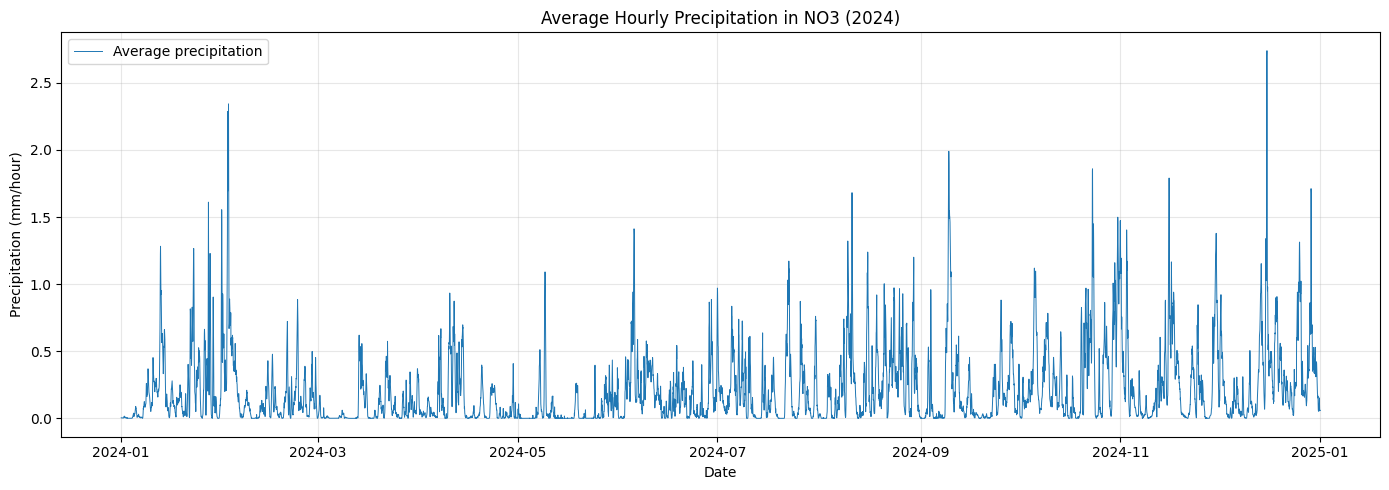

In [ ]:

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    precipitation_no3["time"],
    precipitation_no3["precipitation_mean"],
    linewidth=0.7,
    label="Average precipitation"
)

ax.set(
    title="Average Hourly Precipitation in NO3 (2024)",
    xlabel="Date",
    ylabel="Precipitation (mm/hour)"
)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Get ERA5-data based on region code

In [16]:
def get_region_weather(
    region,
    start_date,
    end_date,
    points_df=random_points,
    n_locations=1
):
    """
    Download hourly ERA5 weather data for locations
    sampled within a specified NVE region.

    """

    # Select locations belonging to the region
    region_points = points_df[
        points_df["REGION"] == region
    ]

    if region_points.empty:
        raise ValueError(f"Unknown region: {region}")

    if not 1 <= n_locations <= len(region_points):
        raise ValueError("Invalid number of locations")

    results = []

    for _, point in region_points.head(n_locations).iterrows():

        weather = get_era5_weather(
            latitude=point["latitude"],
            longitude=point["longitude"],
            start_date=start_date,
            end_date=end_date
        )

        weather["REGION"] = region
        weather["latitude"] = point["latitude"]
        weather["longitude"] = point["longitude"]

        results.append(weather)

    return pd.concat(results, ignore_index=True)

NameError: name 'random_points' is not defined

In [ ]:
weather_rm = get_region_weather(
    region="RM", # Test with one of the regions (e.g., "RM" for Region Midt-Norge)
    start_date="2024-01-01",
    end_date="2024-12-31",
    n_locations=1
)

weather_rm

,time,temperature_2m,precipitation,REGION,latitude,longitude
0,2024-01-01 00:00:00+00:00,-3.9,0.0,RM,64.020179,10.35306
1,2024-01-01 01:00:00+00:00,-4.0,0.0,RM,64.020179,10.35306
2,2024-01-01 02:00:00+00:00,-3.9,0.0,RM,64.020179,10.35306
3,2024-01-01 03:00:00+00:00,-3.7,0.0,RM,64.020179,10.35306
4,2024-01-01 04:00:00+00:00,-3.6,0.0,RM,64.020179,10.35306
...,...,...,...,...,...,...
8779,2024-12-31 19:00:00+00:00,-4.1,0.0,RM,64.020179,10.35306
8780,2024-12-31 20:00:00+00:00,-5.3,0.0,RM,64.020179,10.35306
8781,2024-12-31 21:00:00+00:00,-5.8,0.0,RM,64.020179,10.35306
8782,2024-12-31 22:00:00+00:00,-6.4,0.0,RM,64.020179,10.35306
